In [1]:
import tensorflow as tf
import pandas as pd
import requests
from io import BytesIO

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
base = (
    "https://huggingface.co/datasets/"
    "uitnlp/vietnamese_students_feedback/"
    "resolve/refs%2Fconvert%2Fparquet/default"
)

data = {}

for split in ["train", "validation", "test"]:
    url = f"{base}/{split}/0000.parquet"
    response = requests.get(url, timeout=60)
    response.raise_for_status()

    df = pd.read_parquet(BytesIO(response.content))
    data[split] = df

    print(f"{split}: {len(df)} mẫu")

train_df = data["train"]
val_df = data["validation"]
test_df = data["test"]

print("\nCác cột:", train_df.columns.tolist())
print("\nPhân bố nhãn:")
print(train_df["sentiment"].value_counts().sort_index())

display(train_df.head(10))

assert len(train_df) == 11426
assert len(val_df) == 1583
assert len(test_df) == 3166
assert {"sentence", "sentiment"}.issubset(train_df.columns)

print("\nDATASET OK!")

train: 11426 mẫu
validation: 1583 mẫu
test: 3166 mẫu

Các cột: ['sentence', 'sentiment', 'topic']

Phân bố nhãn:
sentiment
0    5325
1     458
2    5643
Name: count, dtype: int64


,sentence,sentiment,topic
0,slide giáo trình đầy đủ .,2,1
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,0
2,đi học đầy đủ full điểm chuyên cần .,0,1
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,0
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,0
5,"giảng viên đảm bảo thời gian lên lớp , tích cự...",2,0
6,"em sẽ nợ môn này , nhưng em sẽ học lại ở các h...",1,3
7,"thời lượng học quá dài , không đảm bảo tiếp th...",0,1
8,"nội dung môn học có phần thiếu trọng tâm , hầu...",0,1
9,cần nói rõ hơn bằng cách trình bày lên bảng th...,0,1



DATASET OK!


========== DATASET ==========
Train: (11426, 1)
Validation: (1583, 1)
Test: (3166, 1)

Vocabulary Size: 2487

========== MODEL SUMMARY ==========


Model: "Sentiment_RNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ comment             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 60)        │          0 │ comment[0][0]     │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 60, 64)    │    768,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 60)        │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rnn (SimpleRNN)     │ (None, 64)        │      8,256 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ rnn[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 3)         │        195 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 776,451 (2.96 MB)

 Trainable params: 776,451 (2.96 MB)

 Non-trainable params: 0 (0.00 B)


========== START TRAINING ==========
Epoch 1/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7364 - loss: 0.6357
Epoch 1: val_loss improved from None to 0.33259, saving model to results_rnn_dropout03_E30_seed42/best_model.keras

Epoch 1: finished saving model to results_rnn_dropout03_E30_seed42/best_model.keras
179/179 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - accuracy: 0.8349 - loss: 0.4630 - val_accuracy: 0.8958 - val_loss: 0.3326
Epoch 2/30
178/179 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9002 - loss: 0.3133
Epoch 2: val_loss improved from 0.33259 to 0.31436, saving model to results_rnn_dropout03_E30_seed42/best_model.keras

Epoch 2: finished saving model to results_rnn_dropout03_E30_seed42/best_model.keras
179/179 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.9063 - loss: 0.2983 - val_accuracy: 0.9033 - val_loss: 0.3144
Epoch 3/30
178/179 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9193 - loss: 0.2503
Epoch 3: val_loss improved from 0.31436 to 0.30018, saving mod

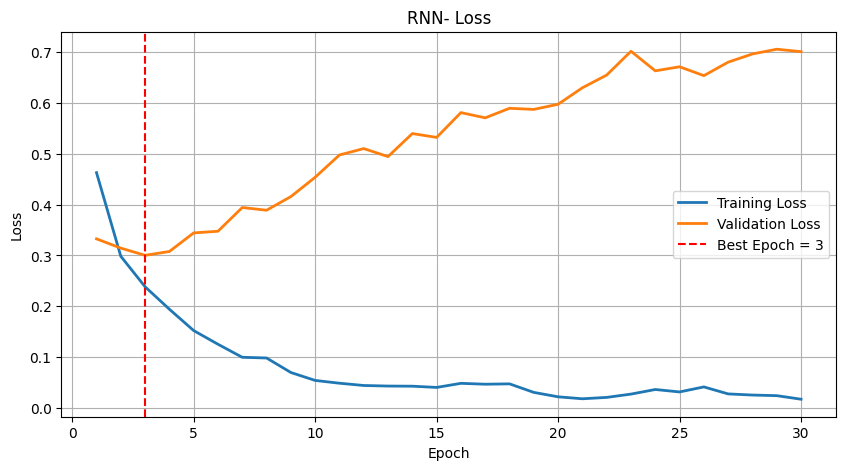

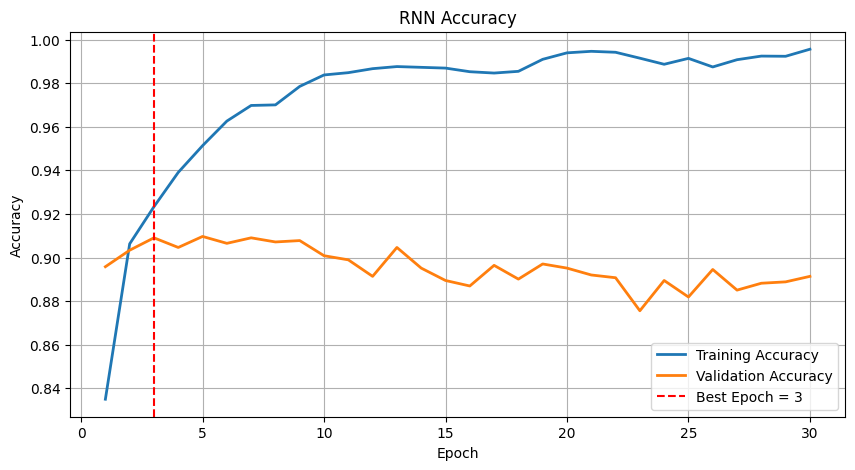


========== EPOCH RESULTS ==========


,Epoch,accuracy,loss,val_accuracy,val_loss
0,1,0.8349,0.4630,0.8958,0.3326
1,2,0.9063,0.2983,0.9033,0.3144
2,3,0.9233,0.2382,0.9090,0.3002
3,4,0.9391,0.1940,0.9046,0.3077
4,5,0.9513,0.1520,0.9097,0.3443
5,6,0.9626,0.1250,0.9065,0.3476
6,7,0.9698,0.0994,0.9090,0.3943
7,8,0.9701,0.0980,0.9071,0.3890
8,9,0.9786,0.0694,0.9078,0.4157
9,10,0.9838,0.0538,0.9008,0.4538



========== COMPLETED ==========
Best Model: results_rnn_dropout03_E30_seed42/best_model.keras
Training History: results_rnn_dropout03_E30_seed42/history.csv
Validation Report: results_rnn_dropout03_E30_seed42/validation_report.txt
Loss Figure: results_rnn_dropout03_E30_seed42/loss.png
Accuracy Figure: results_rnn_dropout03_E30_seed42/accuracy.png


In [5]:


import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ============================================================
# 1. CAU HINH
# ============================================================

MAX_EPOCHS = 30
BATCH_SIZE = 64
LEARNING_RATE = 0.001

MAX_TOKENS = 12000
SEQ_LENGTH = 60

EMBED_DIM = 64
RNN_UNITS = 64

DROPOUT_RATE = 0.3

SEED = 42

# Thu muc rieng, khong ghi de model cu
OUTPUT_DIR = Path(
    f"results_rnn_dropout03_E{MAX_EPOCHS}_seed{SEED}"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / "best_model.keras"
HISTORY_PATH = OUTPUT_DIR / "history.csv"

# Khoi tao lai model tu dau
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

# ============================================================
# 2. CHUAN BI DU LIEU
# ============================================================

def prepare_data(df):

    # Van ban -> TensorFlow string
    texts = (
        df["sentence"]
        .fillna("")
        .astype(str)
        .tolist()
    )

    x = tf.constant(texts, dtype=tf.string)
    x = tf.expand_dims(x, axis=-1)

    # Nhan -> TensorFlow int32
    labels = pd.to_numeric(
        df["sentiment"],
        errors="raise"
    ).to_numpy(dtype=np.int32)

    if not np.isin(labels, [0, 1, 2]).all():
        raise ValueError("Nhan khong hop le!")

    y = tf.constant(labels, dtype=tf.int32)

    return x, y


x_train, y_train = prepare_data(train_df)
x_val, y_val = prepare_data(val_df)
x_test, y_test = prepare_data(test_df)

print("========== DATASET ==========")
print("Train:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)

# ============================================================
# 3. TEXT VECTORIZATION
# ============================================================

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQ_LENGTH,
    standardize="lower_and_strip_punctuation",
    split="whitespace"
)

# Chi hoc tu vung tren tap Train
vectorizer.adapt(x_train)

VOCAB_SIZE = len(vectorizer.get_vocabulary())

print("\nVocabulary Size:", VOCAB_SIZE)

# ============================================================
# 4. XAY DUNG MO HINH RNN
# ============================================================

inputs = tf.keras.Input(
    shape=(1,),
    dtype=tf.string,
    name="comment"
)

# Van ban -> Token ID
x = vectorizer(inputs)

# Token ID -> Embedding
x = tf.keras.layers.Embedding(
    input_dim=MAX_TOKENS,
    output_dim=EMBED_DIM,
    mask_zero=True,
    name="embedding"
)(x)

# SimpleRNN - 64 hidden units
x = tf.keras.layers.SimpleRNN(
    units=RNN_UNITS,
    activation="tanh",
    name="rnn"
)(x)

# ============================================================
# DROPOUT
# ============================================================

x = tf.keras.layers.Dropout(
    rate=DROPOUT_RATE,
    name="dropout"
)(x)

# ============================================================
# OUTPUT - 3 NHAN CAM XUC
# ============================================================

outputs = tf.keras.layers.Dense(
    units=3,
    activation="softmax",
    name="output"
)(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="Sentiment_RNN"
)

print("\n========== MODEL SUMMARY ==========")
model.summary()

# ============================================================
# 5. COMPILE
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ============================================================
# 6. MODEL CHECKPOINT
# ============================================================

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(MODEL_PATH),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# ============================================================
# 7. HUAN LUYEN
# ============================================================

print("\n========== START TRAINING ==========")

start_time = time.time()

history = model.fit(
    x_train,
    y_train,

    validation_data=(x_val, y_val),

    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,

    callbacks=[checkpoint],

    verbose=1
)

training_time = time.time() - start_time

print("\n========== TRAINING FINISHED ==========")

# ============================================================
# 8. LUU TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history.history)

actual_epochs = len(history_df)

history_df.insert(
    0,
    "Epoch",
    np.arange(1, actual_epochs + 1)
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

# ============================================================
# 9. TIM EPOCH TOT NHAT
# ============================================================

best_idx = int(
    np.argmin(history_df["val_loss"].to_numpy())
)

best_epoch = best_idx + 1

best_val_loss = history_df["val_loss"].iloc[best_idx]
best_val_acc = history_df["val_accuracy"].iloc[best_idx]

print("\n========== TRAINING SUMMARY ==========")

print("Configured Epochs:", MAX_EPOCHS)
print("Completed Epochs:", actual_epochs)

print("Best Epoch:", best_epoch)

print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Validation Accuracy at Best Epoch: {best_val_acc:.4f}")

print(f"Training Time: {training_time/60:.2f} minutes")

print("Model Path:", MODEL_PATH)
print("History Path:", HISTORY_PATH)

# ============================================================
# 10. LOAD CHECKPOINT TOT NHAT
# ============================================================

best_model = tf.keras.models.load_model(
    str(MODEL_PATH)
)

print("\nBest model loaded successfully!")

# ============================================================
# 11. DANH GIA TREN VALIDATION
# ============================================================

val_probs = best_model.predict(
    x_val,
    batch_size=BATCH_SIZE,
    verbose=0
)

val_pred = np.argmax(val_probs, axis=1)
val_true = y_val.numpy()

val_accuracy = accuracy_score(val_true, val_pred)

val_macro_f1 = f1_score(
    val_true,
    val_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

print("\n========== VALIDATION RESULTS ==========")

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Macro-F1: {val_macro_f1:.4f}")

report = classification_report(
    val_true,
    val_pred,
    labels=[0, 1, 2],
    target_names=[
        "Negative",
        "Neutral",
        "Positive"
    ],
    zero_division=0
)

print("\nCLASSIFICATION REPORT:")
print(report)

# Luu ket qua validation
with open(
    OUTPUT_DIR / "validation_report.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write(f"Best Epoch: {best_epoch}\n")
    f.write(f"Best Val Loss: {best_val_loss:.6f}\n")
    f.write(f"Validation Accuracy: {val_accuracy:.6f}\n")
    f.write(f"Validation Macro-F1: {val_macro_f1:.6f}\n\n")
    f.write(report)

# ============================================================
# 12. VE BIEU DO LOSS
# ============================================================

epochs_axis = history_df["Epoch"]

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_axis,
    history_df["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epochs_axis,
    history_df["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN- Loss")

plt.legend()
plt.grid(True)

plt.savefig(
    OUTPUT_DIR / "loss.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. VE BIEU DO ACCURACY
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_axis,
    history_df["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    epochs_axis,
    history_df["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

plt.axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN Accuracy")

plt.legend()
plt.grid(True)

plt.savefig(
    OUTPUT_DIR / "accuracy.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 14. HIEN THI BANG EPOCH
# ============================================================

print("\n========== EPOCH RESULTS ==========")

display(history_df.round(4))

# ============================================================
# 15. TONG KET
# ============================================================

print("\n========== COMPLETED ==========")

print("Best Model:", MODEL_PATH)
print("Training History:", HISTORY_PATH)
print("Validation Report:", OUTPUT_DIR / "validation_report.txt")
print("Loss Figure:", OUTPUT_DIR / "loss.png")
print("Accuracy Figure:", OUTPUT_DIR / "accuracy.png")


Model loaded: results_rnn_dropout03_E30_seed42/best_model.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step

========== TEST RESULTS ==========
Accuracy:  0.8853
Precision: 0.8026
Recall:    0.6573
Macro-F1:  0.6692

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

    Negative       0.86      0.94      0.90      1409
     Neutral       0.63      0.11      0.19       167
    Positive       0.91      0.92      0.91      1590

    accuracy                           0.89      3166
   macro avg       0.80      0.66      0.67      3166
weighted avg       0.88      0.89      0.87      3166



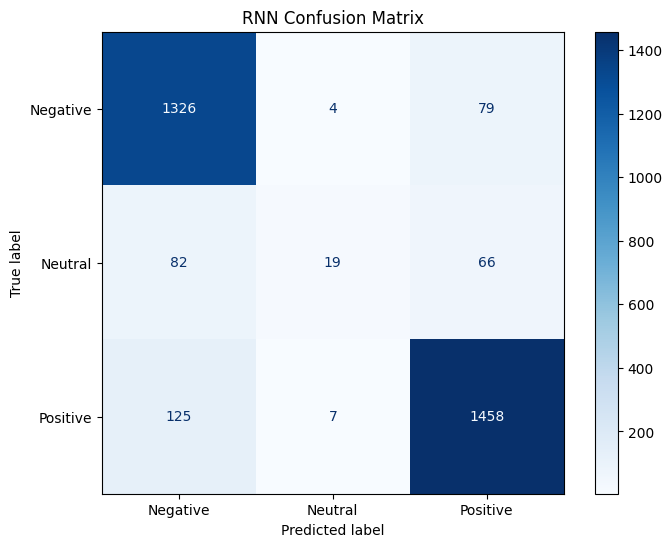


========== WRONG PREDICTIONS ==========
Total wrong predictions: 363


,sentence,sentiment,Predicted
6,tính điểm thi đua các nhóm .,2,1
12,trong trường macbook thầy số hai thì không có ...,2,0
27,cách mà cô tiếp cận với sinh viên .,1,2
31,"phòng học thoáng mát , trang thiết bị đầy đủ .",2,0
35,môn học này giúp chúng em hiểu ra những vấn đề...,1,2
41,ổn .,1,2
45,phần lớn chỉ là lý thuyết và bài tập .,2,0
53,như vậy tụi em sẽ định hướng tốt hơn và tập tr...,1,0
55,ấn tượng nhất doubledot dạy không cần máy chiế...,2,0
57,đưa nhiều bài tập khó mà có lời giải cho sinh ...,2,0



========== EVALUATION COMPLETED ==========
Model: results_rnn_dropout03_E30_seed42/best_model.keras
Test Accuracy: 88.53%
Test Macro-F1: 66.92%
Results: results_rnn_dropout03_E30_seed42/test_evaluation


In [7]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CAU HINH
# ============================================================

BATCH_SIZE = 64

LABELS = [
    "Negative",
    "Neutral",
    "Positive"
]

# Lay dung checkpoint tu Buoc 3
MODEL_FILE = Path(MODEL_PATH)

if not MODEL_FILE.exists():
    raise FileNotFoundError(
        f"Khong tim thay model: {MODEL_FILE}"
    )

OUTPUT_EVAL = MODEL_FILE.parent / "test_evaluation"
OUTPUT_EVAL.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. LOAD MODEL TOT NHAT
# ============================================================

best_model = tf.keras.models.load_model(
    str(MODEL_FILE)
)

print("Model loaded:", MODEL_FILE)

# ============================================================
# 3. DU DOAN TREN TAP TEST
# ============================================================

test_probs = best_model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

y_pred = np.argmax(test_probs, axis=1)
y_true = y_test.numpy().reshape(-1)

# ============================================================
# 4. TINH CAC CHI SO
# ============================================================

test_accuracy = accuracy_score(
    y_true, y_pred
)

test_precision = precision_score(
    y_true, y_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_true, y_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    y_true, y_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

print("\n========== TEST RESULTS ==========")

print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"Macro-F1:  {test_macro_f1:.4f}")

# ============================================================
# 5. CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=LABELS,
    zero_division=0
)

print("\n========== CLASSIFICATION REPORT ==========")
print(report)

# ============================================================
# 6. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LABELS
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("RNN Confusion Matrix")

plt.savefig(
    OUTPUT_EVAL / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 7. LUU CAC CHI SO
# ============================================================

metrics = {
    "model": "SimpleRNN + Dropout(0.3)",
    "test_samples": int(len(y_true)),
    "test_accuracy": float(test_accuracy),
    "test_precision_macro": float(test_precision),
    "test_recall_macro": float(test_recall),
    "test_macro_f1": float(test_macro_f1)
}

with open(
    OUTPUT_EVAL / "test_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics, f, indent=4)

with open(
    OUTPUT_EVAL / "classification_report.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

# ============================================================
# 8. LUU KET QUA DU DOAN TUNG CAU
# ============================================================

pred_df = test_df[
    ["sentence", "sentiment"]
].copy().reset_index(drop=True)

pred_df["Predicted"] = y_pred

pred_df["Correct"] = (
    pred_df["sentiment"] == pred_df["Predicted"]
)

for i, label in enumerate(LABELS):
    pred_df[f"Prob_{label}"] = test_probs[:, i]

pred_df.to_csv(
    OUTPUT_EVAL / "test_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 9. HIEN THI 10 CAU DU DOAN SAI
# ============================================================

wrong_df = pred_df[
    pred_df["Correct"] == False
]

print("\n========== WRONG PREDICTIONS ==========")

print("Total wrong predictions:", len(wrong_df))

display(
    wrong_df[
        ["sentence", "sentiment", "Predicted"]
    ].head(10)
)

# ============================================================
# 10. TONG KET
# ============================================================

print("\n========== EVALUATION COMPLETED ==========")

print("Model:", MODEL_FILE)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Macro-F1: {test_macro_f1 * 100:.2f}%")
print("Results:", OUTPUT_EVAL)
